# Лабораторна №4. Прогноз відтоку клієнтів Telco

Токарчук Роман, група 507 · Тема 1.1

Я взяв [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn)
і поставив задачу бінарної класифікації. Модель отримує дані про клієнта й
повертає оцінку ймовірності того, що він припинив користуватися послугами
за останній місяць (`Churn = Yes`). Правильні відповіді беру зі стовпця `Churn`.

[Умова](https://github.com/maxvonlancaster/ida-labs/blob/main/assignement-4.ipynb)

## 1. Аналіз даних

CSV з [репозиторію IBM](https://github.com/IBM/telco-customer-churn-on-icp4d/blob/master/data/Telco-Customer-Churn.csv)
містить один рядок на клієнта. `customerID` ідентифікує запис. `gender`,
`SeniorCitizen`, `Partner` і `Dependents` описують клієнта.
`tenure` показує кількість місяців у компанії. `Contract`,
`PaperlessBilling` і `PaymentMethod` описують контракт та оплату,
`MonthlyCharges` і `TotalCharges` — місячні й накопичені нарахування.
Решта ознак показують, які послуги підключені.

**Питання**

1. Чи вища частка відтоку у клієнтів із помісячним контрактом, ніж у клієнтів із річним або дворічним?
2. Чи менше часу в компанії провели клієнти, які пішли?

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from sklearn.metrics import ConfusionMatrixDisplay, PrecisionRecallDisplay

from lab4 import (NUMERIC, TARGET, evaluate_models, fit_models, load_churn,
                  mcnemar_test, prepare_churn, split_churn)

raw = load_churn()
print(f"CSV: {raw.shape[0]:,} рядків, {raw.shape[1]} стовпець")
print(f"Повні дублікати: {raw.duplicated().sum()}")
print(f"Повторні customerID: {raw['customerID'].duplicated().sum()}")
display(pd.DataFrame({
    "Тип": raw.dtypes.astype(str),
    "Пропуски": raw.isna().sum(),
    "Унікальні значення": raw.nunique(),
}))
print("tenure для записів без TotalCharges:")
display(raw.loc[raw["TotalCharges"].isna(), "tenure"].value_counts().rename("Клієнтів"))

CSV: 7,043 рядків, 21 стовпець
Повні дублікати: 0
Повторні customerID: 0


,Тип,Пропуски,Унікальні значення
customerID,str,0,7043
gender,str,0,2
SeniorCitizen,int64,0,2
Partner,str,0,2
Dependents,str,0,2
tenure,int64,0,73
PhoneService,str,0,2
MultipleLines,str,0,3
InternetService,str,0,3
OnlineSecurity,str,0,3


tenure для записів без TotalCharges:


tenure
0    11
Name: Клієнтів, dtype: int64

`TotalCharges` прочитав як число. Знайшов 11 порожніх значень, усі
при `tenure = 0`. Для цих записів поставив 0 накопичених нарахувань.
Дублікатів немає. `customerID` залишив індексом, а `Churn` перевів
у 0/1. Додав `InternetAddons` як кількість підключених додаткових
інтернет-послуг, від 0 до 6.

Я відклав 20% клієнтів під тест і зберіг співвідношення класів в обох
частинах. Далі статистика й графіки EDA побудовані на train.

In [2]:
train, test = split_churn(prepare_churn(raw))
print(f"Train: {len(train):,}, test: {len(test):,}")
numeric = train[NUMERIC]
display(numeric.describe().T.round(2))

q1 = numeric.quantile(0.25)
q3 = numeric.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
display(pd.DataFrame({
    "Нижня межа": lower,
    "Верхня межа": upper,
    "За межами IQR": (numeric.lt(lower) | numeric.gt(upper)).sum(),
}).round(2))

Train: 5,634, test: 1,409


,count,mean,std,min,25%,50%,75%,max
tenure,5634.0,32.485091,24.568744,0.0,9.0,29.0,55.0,72.0
MonthlyCharges,5634.0,64.929961,30.138105,18.4,35.6625,70.5,90.0,118.75
TotalCharges,5634.0,2299.334682,2279.204278,0.0,402.975,1394.925,3835.825,8684.8
InternetAddons,5634.0,2.05804,1.854652,0.0,0.0,2.0,3.0,6.0


,Нижня межа,Верхня межа,За межами IQR
tenure,-60.0,124.0,0
MonthlyCharges,-45.84,171.51,0
TotalCharges,-4746.3,8985.1,0
InternetAddons,-4.5,7.5,0


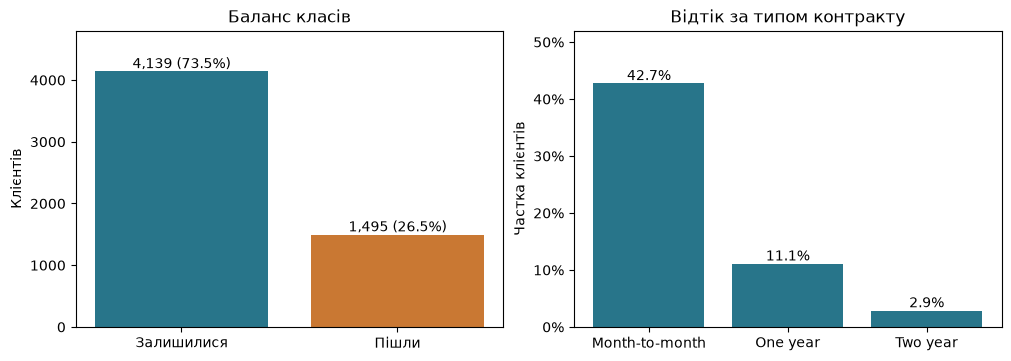

,Клієнтів,Частка відтоку
Contract,,
Month-to-month,3102,0.427
One year,1173,0.111
Two year,1359,0.029


In [3]:
kept, churned = "Залишилися", "Пішли"
class_order = [kept, churned]
colors = ["#28758a", "#c97833"]
counts = train[TARGET].value_counts().reindex([0, 1])
contracts = (train.groupby("Contract")[TARGET].agg(["size", "mean"])
             .reindex(["Month-to-month", "One year", "Two year"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
bars = ax1.bar(class_order, counts, color=colors)
ax1.bar_label(bars, labels=[f"{n:,} ({n / len(train):.1%})" for n in counts])
ax1.set(title="Баланс класів", ylabel="Клієнтів", ylim=(0, 4800))

bars = ax2.bar(contracts.index, contracts["mean"], color="#28758a")
ax2.bar_label(bars, labels=[f"{v:.1%}" for v in contracts["mean"]])
ax2.yaxis.set_major_formatter(PercentFormatter(1))
ax2.set(title="Відтік за типом контракту", ylabel="Частка клієнтів", ylim=(0, 0.52))
plt.show()
display(contracts.rename(columns={"size": "Клієнтів", "mean": "Частка відтоку"}).round(3))

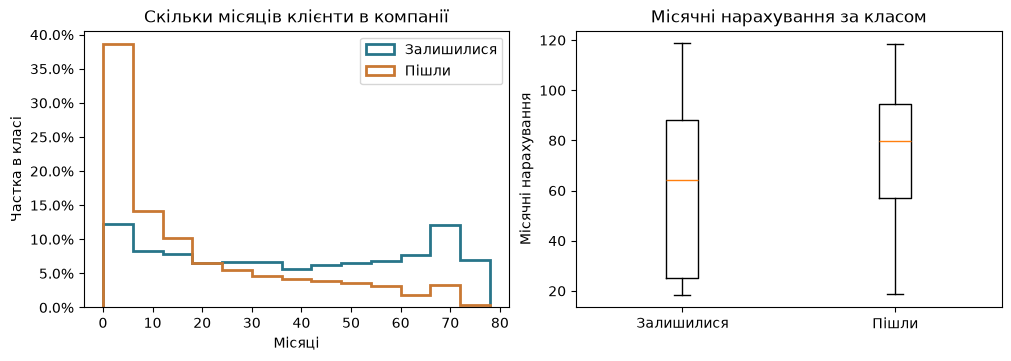

Churn
Залишилися    38.0
Пішли         10.0
Name: Медіана tenure, місяців, dtype: float64

In [4]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
tenure_by_class = [train.loc[train[TARGET].eq(label), "tenure"] for label in [0, 1]]
bins = np.arange(0, 79, 6)
for tenure, name, color in zip(tenure_by_class, class_order, colors):
    ax1.hist(tenure, bins=bins, weights=np.ones(len(tenure)) / len(tenure),
             histtype="step", linewidth=2, label=name, color=color)
ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax1.set(title="Скільки місяців клієнти в компанії", xlabel="Місяці", ylabel="Частка в класі")
ax1.legend()

charges = [train.loc[train[TARGET].eq(label), "MonthlyCharges"] for label in [0, 1]]
ax2.boxplot(charges, tick_labels=class_order)
ax2.set(title="Місячні нарахування за класом", ylabel="Місячні нарахування")
plt.show()

display(train.groupby(TARGET)["tenure"].median()
        .rename(index={0: kept, 1: churned}).rename("Медіана tenure, місяців"))

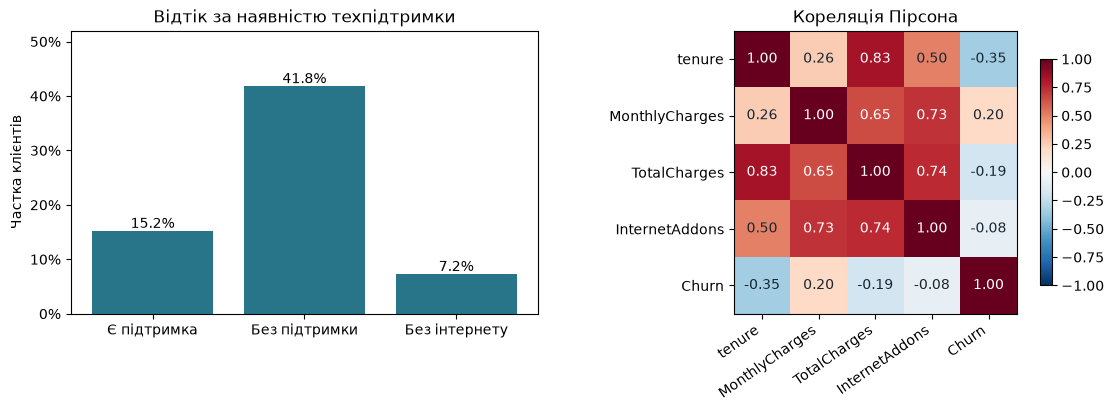

In [5]:
support = (train.groupby("TechSupport")[TARGET].agg(["size", "mean"])
           .reindex(["Yes", "No", "No internet service"]))
correlation = train[NUMERIC + [TARGET]].corr()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
bars = ax1.bar(["Є підтримка", "Без підтримки", "Без інтернету"],
               support["mean"], color="#28758a")
ax1.bar_label(bars, labels=[f"{v:.1%}" for v in support["mean"]])
ax1.yaxis.set_major_formatter(PercentFormatter(1))
ax1.set(title="Відтік за наявністю техпідтримки", ylabel="Частка клієнтів", ylim=(0, 0.52))

heatmap = ax2.imshow(correlation, cmap="RdBu_r", vmin=-1, vmax=1)
positions = range(len(correlation))
ax2.set_xticks(positions, correlation.columns, rotation=35, ha="right")
ax2.set_yticks(positions, correlation.index)
for i, row in enumerate(correlation.to_numpy()):
    for j, value in enumerate(row):
        ax2.text(j, i, f"{value:.2f}", ha="center", va="center",
                 color="white" if abs(value) > 0.65 else "#182632")
ax2.set_title("Кореляція Пірсона")
fig.colorbar(heatmap, ax=ax2, shrink=0.8)
plt.show()

На train помісячний контракт має відтік 42,7%, річний — 11,1%,
дворічний — 2,9%. Медіана `tenure` у клієнтів, які пішли, становить
10 місяців, у решти — 38. Обидві очікувані відмінності видно в даних.
`tenure` і `TotalCharges` сильно корелюють ($r = 0{,}83$), бо
накопичена сума зростає з часом користування. Серед клієнтів із
підключеним інтернетом відтік вищий у тих, хто не має техпідтримки
(41,8% проти 15,2%). Ці зв’язки описують групи у вибірці. Для висновку
про причину відтоку знадобився б окремий дизайн дослідження.

Числові ознаки перевірив за межами $Q_1 - 1{,}5\,IQR$ і $Q_3 + 1{,}5\,IQR$.
За цим правилом у train немає викидів.

## 2. Навчання й порівняння моделей

Числові ознаки масштабував через `StandardScaler`, категорії перетворив
через `OneHotEncoder`. Обидва кроки всередині `Pipeline` вчаться на
навчальній частині кожного фолду. Я порівняв три алгоритми.

- **Logistic Regression** дає оцінку за зваженою сумою ознак. Вона швидка, але взаємодії ознак треба задавати окремо.
- **Random Forest** усереднює прогнози випадкових дерев. Він знаходить нелінійні зв’язки, але важче пояснити конкретний прогноз.
- **Gradient Boosting** послідовно додає дерева, які коригують попередній прогноз. Він також враховує взаємодії й чутливий до глибини та кількості дерев.

Для кожного алгоритму підібрав параметри через `GridSearchCV` на тих
самих п’яти стратифікованих фолдах. Критерій вибору — середній F1
для класу відтоку. Цей клас займає близько 27% даних, тому одночасно
дивлюся і на precision, і на recall. Для орієнтиру додав класифікатор,
який завжди видає найчастіший клас.

In [6]:
models, cv_results = fit_models(train)
selected = cv_results.index[0]
print(f"Вибір за середнім CV F1: {selected}")
display(cv_results.round(4))

Вибір за середнім CV F1: Logistic Regression


,CV F1,CV F1 std,Параметри
Модель,,,
Logistic Regression,0.5979,0.0297,{'C': 10}
Gradient Boosting,0.5931,0.0247,"{'max_depth': 3, 'n_estimators': 75}"
Random Forest,0.5781,0.0215,"{'max_depth': 10, 'min_samples_leaf': 3}"


,Accuracy,Precision,Recall,F1,ROC AUC,Average precision
Модель,,,,,,
Logistic Regression,0.8055,0.6572,0.5588,0.6040,0.8412,0.6280
Random Forest,0.8027,0.6678,0.5107,0.5788,0.8396,0.6535
Gradient Boosting,0.8041,0.6690,0.5187,0.5843,0.8447,0.6636
Baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.2654


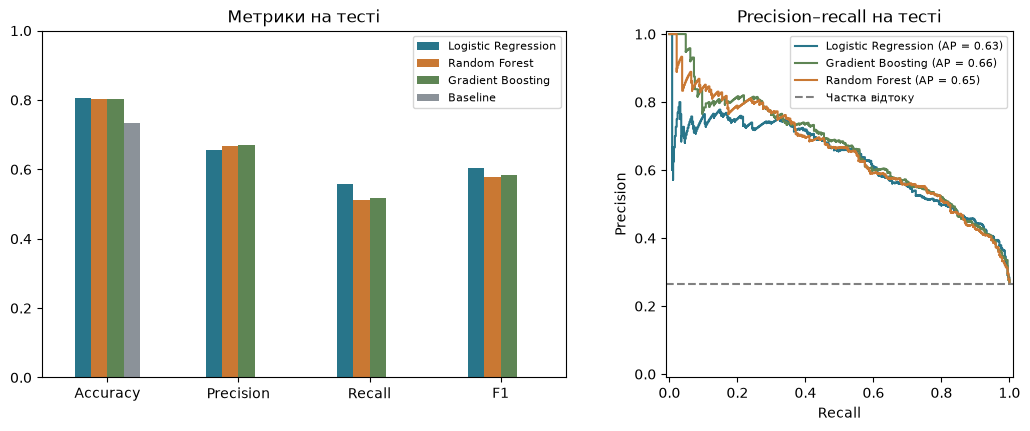

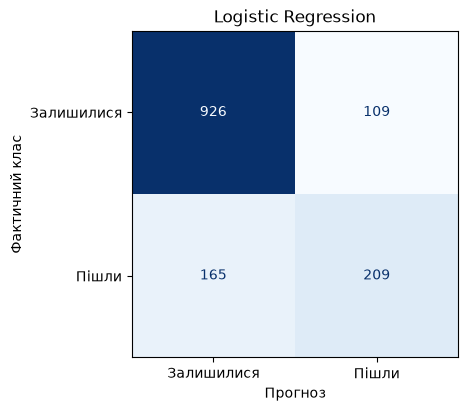

In [7]:
metrics, predictions, probabilities = evaluate_models(models, test)
display(metrics.round(4))

model_colors = dict(zip(metrics.index, ["#28758a", "#c97833", "#5e8554", "#8b9299"]))
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.2), layout="constrained")
metrics[["Accuracy", "Precision", "Recall", "F1"]].T.plot.bar(
    ax=ax1, color=model_colors, rot=0)
ax1.set(title="Метрики на тесті", ylim=(0, 1))
ax1.legend(fontsize=8)

for name in cv_results.index:
    PrecisionRecallDisplay.from_predictions(
        test[TARGET], probabilities[name], name=name, ax=ax2,
        curve_kwargs={"color": model_colors[name]})
ax2.axhline(test[TARGET].mean(), color="gray", linestyle="--",
            label="Частка відтоку")
ax2.set(title="Precision–recall на тесті", xlabel="Recall", ylabel="Precision")
ax2.legend(fontsize=8)
plt.show()

fig, ax = plt.subplots(figsize=(5, 4), layout="constrained")
ConfusionMatrixDisplay.from_predictions(test[TARGET], predictions[selected],
                                       display_labels=class_order, ax=ax,
                                       colorbar=False, cmap="Blues")
ax.set(title=selected, xlabel="Прогноз", ylabel="Фактичний клас")
plt.show()

## 3. Перевірка статистичної гіпотези

Порівнюю Logistic Regression і Random Forest на тих самих тестових
клієнтах. $H_0$ — обидві моделі мають однакову ймовірність правильної
класифікації. $H_1$ — ці ймовірності різні. Рівень значущості
$\alpha = 0{,}05$.

Використав точний двосторонній тест Мак-Немара. Він рахує клієнтів,
для яких правильна лише одна з моделей. За $H_0$ такі випадки
повинні ділитися між моделями з імовірністю $0{,}5$, тому застосовую
біноміальний тест. Так я перевіряю різницю в accuracy. F1 окремо
оцінюю за таблицею метрик.

In [8]:
first, second = "Logistic Regression", "Random Forest"
paired, p_value = mcnemar_test(test[TARGET], predictions[first], predictions[second])
display(pd.DataFrame(
    paired,
    index=[f"{first}: правильно", f"{first}: помилка"],
    columns=[f"{second}: правильно", f"{second}: помилка"],
))
print(f"p-value = {p_value:.4f} (α = 0.05)")
print("Відхиляю H₀." if p_value < 0.05 else "Підстав відхилити H₀ немає.")

,Random Forest: правильно,Random Forest: помилка
Logistic Regression: правильно,1086,49
Logistic Regression: помилка,45,229


p-value = 0.7572 (α = 0.05)
Підстав відхилити H₀ немає.


## Висновок

За середнім F1 на крос-валідації я обрав логістичну регресію з `C=10`.
На тесті отримав F1 0,604 та accuracy 80,6%. Модель виявила 209 із
374 клієнтів, які пішли. Градієнтний бустинг мав найвищу Average
Precision (0,664), тож на цій вибірці він краще ранжував клієнтів
за ризиком за цією метрикою.

У 49 випадках правильно відповіла лише логістична регресія, у 45 —
лише випадковий ліс. При $p = 0{,}7572$ я не відхиляю гіпотезу
про однакову accuracy цих двох моделей.